# TP2 - Tecnología Digital VI: Clasificación de Género Musical (Spotify)

Integrantes: Federico Del Cuadro, Bautista Goya, Timo Doeswijk.

El objetivo de este trabajo fue predecir el género de una canción a partir de sus características de audio y su popularidad. Trabajamos con seis géneros: **acoustic**, **classical**, **electronic**, **hip-hop**, **jazz** y **rock**.

### Índice

- **0.** Preparación del entorno
- **1.** Carga de datos
- **2.** Análisis Exploratorio de Datos (EDA)
- **3.** Preprocesamiento de los datos
- **4.** Criterios de evaluación
- **5.** Modelos y optimización de hiperparámetros con Optuna
- **6.** Configuración elegida y validación cruzada
- **7.** Evaluación sobre la reserva
- **8.** Implementación de MAP@3
- **9.** Comparación de modelos: F1 macro vs. MAP@3
- **10.** Optimización orientada a MAP@3
- **11.** Métricas según el caso de negocio
- **12.** Entrenamiento final
- **13.** Generación del archivo para Kaggle
- **14.** Conclusiones

Analizamos los datos, definimos su preprocesamiento y entrenamos **CatBoost** y **LightGBM**. Seleccionamos sus hiperparámetros con **Optuna**, combinamos sus probabilidades y ajustamos las predicciones cuando encontramos canciones cercanas con etiquetas coincidentes en el entrenamiento.

Para reproducir el trabajo, colocamos `train.csv` y `test.csv` en la misma carpeta que este notebook y ejecutamos las celdas en orden. Incluimos los resultados de los estudios de Optuna y el código para repetirlos. El archivo para Kaggle se guarda en **resultados_fede/submission.csv**.

## 0. Preparación del entorno

Importamos las herramientas para manipular los datos, construir los gráficos, preparar las variables y entrenar los modelos. Usamos la semilla **67** y dos hilos de procesamiento.

La variable **repetir_busqueda** controla los estudios de F1 macro: con **False**, usamos sus resultados guardados; con **True**, repetimos las 20 pruebas de cada modelo y las 40 del ensamble. En ambos casos se recalculan las predicciones de validación y se entrena el modelo final. El estudio adicional de MAP@3 de la sección 10 se ejecuta siempre sobre esas predicciones.

In [26]:
# Si falta Optuna en este kernel, ejecutar: %pip install optuna
# Luego reiniciar el kernel y ejecutar las celdas en orden.
from pathlib import Path
from io import StringIO
import json
import copy
import hashlib
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import optuna

from IPython.display import display
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from threadpoolctl import threadpool_limits

optuna.logging.set_verbosity(optuna.logging.WARNING)

c:\Users\timod\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [64]:
random_state = 67
np.random.seed(random_state)
n_jobs = 2
repetir_busqueda = False
pruebas_por_modelo = 20
pruebas_ensamble = 40

carpeta = Path.cwd()
if not (carpeta / 'train.csv').exists():
    carpeta = carpeta / 'TP2 TD6'
salida = carpeta / 'resultados_entrega'
salida.mkdir(exist_ok=True)

## 1. Carga de datos

In [28]:
df = pd.read_csv(carpeta / 'train.csv')
df_kaggle = pd.read_csv(carpeta / 'test.csv')

print('Train:', df.shape)
print('Test:', df_kaggle.shape)
df.head()

Train: (4200, 17)
Test: (1800, 16)


,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,Expected,Id
0,0,143733,False,0.439,0.196,0,-16.093,1,0.0601,0.88000,0.0000,0.0513,0.525,129.581,4,jazz,4271
1,0,261562,False,0.627,0.876,11,-4.391,0,0.0324,0.01590,0.0000,0.0665,0.418,111.950,4,electronic,2078
2,63,190131,False,0.767,0.869,2,-3.381,0,0.0908,0.14000,0.0000,0.2210,0.751,98.208,4,hip-hop,4921
3,48,201440,False,0.374,0.183,9,-13.225,1,0.0281,0.89700,0.0387,0.1090,0.134,82.042,4,acoustic,4206
4,0,168552,True,0.423,0.721,0,-8.070,1,0.1650,0.00792,0.0000,0.3800,0.382,161.926,4,rock,2423


In [29]:
print("Nulos en train:", df.isnull().sum().sum())
print("Nulos en test:", df_kaggle.isnull().sum().sum(), "\n")
print("Ids repetidos entre train y test:", len(set(df["Id"]) & set(df_kaggle["Id"])),"\n")
df.info()

Nulos en train: 0
Nulos en test: 0 

Ids repetidos entre train y test: 0 

<class 'pandas.DataFrame'>
RangeIndex: 4200 entries, 0 to 4199
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   popularity        4200 non-null   int64  
 1   duration_ms       4200 non-null   int64  
 2   explicit          4200 non-null   bool   
 3   danceability      4200 non-null   float64
 4   energy            4200 non-null   float64
 5   key               4200 non-null   int64  
 6   loudness          4200 non-null   float64
 7   mode              4200 non-null   int64  
 8   speechiness       4200 non-null   float64
 9   acousticness      4200 non-null   float64
 10  instrumentalness  4200 non-null   float64
 11  liveness          4200 non-null   float64
 12  valence           4200 non-null   float64
 13  tempo             4200 non-null   float64
 14  time_signature    4200 non-null   int64  
 15  Expected          4200 no

### Variables predictoras y variable objetivo

La columna **Expected** contiene el género que queremos predecir. Excluimos **Id** de las variables predictoras porque identifica cada registro; la conservamos para asociar las predicciones con las canciones al generar el CSV.

Codificamos los géneros con **LabelEncoder**, que asigna un número a cada clase. Al finalizar, utilizamos la transformación inversa para recuperar sus nombres. También comprobamos que el conjunto de prueba tenga las mismas variables predictoras que el de entrenamiento.

Definimos **key** y **time_signature** como variables categóricas. Para la búsqueda de canciones similares usamos todas las variables predictoras excepto **popularity**: este atributo puede variar sin que cambien las características de audio de una canción.

In [30]:
columnas = [c for c in df.columns if c not in ['Id', 'Expected']]
categorical = ['key', 'time_signature']
columnas_audio = [c for c in columnas if c != 'popularity']

X = df[columnas].copy()
X_kaggle = df_kaggle[columnas].copy()
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(df['Expected'])
generos = label_encoder.classes_
num_clases = len(generos)

assert set(df_kaggle.columns) == set(columnas + ['Id'])
print(dict(enumerate(generos)))
numerical_cols = [c for c in columnas if c not in categorical]

{0: 'acoustic', 1: 'classical', 2: 'electronic', 3: 'hip-hop', 4: 'jazz', 5: 'rock'}


### Separación entre desarrollo y reserva

Dividimos los datos etiquetados de forma estratificada: **85% para desarrollo (3.570 canciones)** y **15% como reserva (630 canciones)**. La estratificación mantiene la proporción de géneros en ambos conjuntos. Usamos la semilla **67**.

Los estudios de Optuna y la calibración utilizan únicamente el conjunto de desarrollo. La reserva se usa para comparar resultados una vez fijados los parámetros; como fue consultada durante el trabajo, sus métricas son un diagnóstico y no una estimación final completamente independiente. Al terminar, entrenamos con todas las canciones etiquetadas para predecir el test de Kaggle.

In [31]:
indices_train, indices_reserva = train_test_split(
    np.arange(len(y)), test_size=0.15, stratify=y, random_state=random_state
)
X_train = X.iloc[indices_train].reset_index(drop=True)
y_train = y[indices_train]
X_reserva = X.iloc[indices_reserva].reset_index(drop=True)
y_reserva = y[indices_reserva]
print('Desarrollo:', len(X_train), '- Reserva:', len(X_reserva))

Desarrollo: 3570 - Reserva: 630


## 2. Análisis Exploratorio de Datos (EDA)

Exploramos la distribución de los géneros, las características de las canciones y las repeticiones de registros. Este análisis nos permite describir los datos y reconocer limitaciones que afectan la interpretación del desempeño.

In [32]:
df_eda = X_train.copy()
df_eda['genero'] = label_encoder.inverse_transform(y_train)

### Distribución de géneros musicales

Contamos las canciones de cada género en el conjunto de desarrollo para revisar si existe un desequilibrio entre clases.

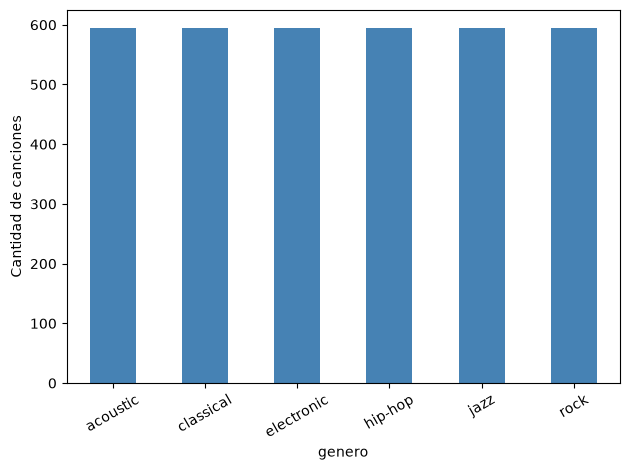

In [33]:
# Visualización 1: distribución de clases del target
df_eda['genero'].value_counts().sort_index().plot.bar(color='steelblue')
plt.ylabel('Cantidad de canciones')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

Las seis clases están balanceadas. Por este motivo, no aplicamos oversampling ni undersampling y trabajamos con la distribución disponible.

### Características de audio por género

Comparamos las distribuciones de **acousticness, instrumentalness, speechiness, energy, danceability y valence** mediante diagramas de caja. Cada gráfico permite observar diferencias entre géneros y la variabilidad dentro de cada clase.

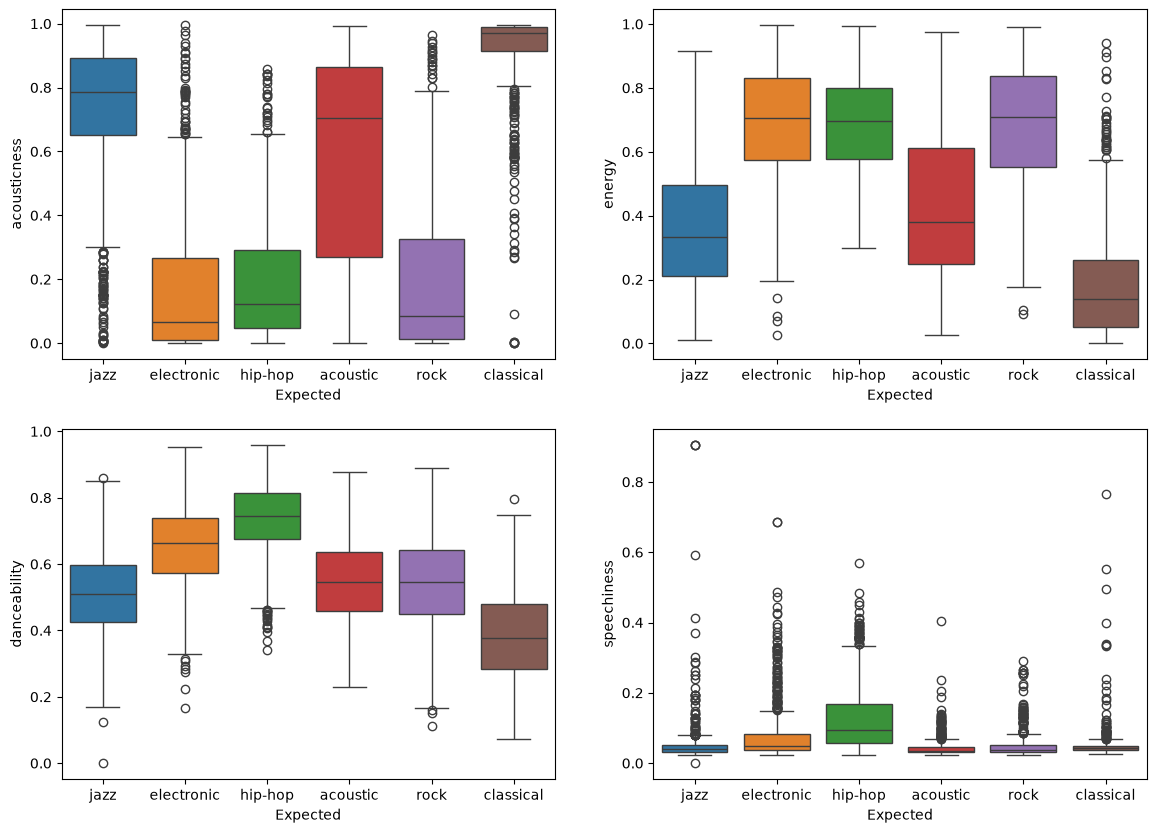

In [34]:
# Visualización 2: distribución de features numéricas clave por género
features_clave = ["acousticness", "energy", "danceability", "speechiness"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()
for i, feat in enumerate(features_clave):
    sns.boxplot(data=df, x="Expected", y=feat, order=df['Expected'].value_counts().index, ax=axes[i], hue="Expected")
plt.show()

Las distribuciones muestran diferencias en el carácter acústico, la instrumentalidad y la presencia de habla, aunque también hay solapamientos entre géneros. Esto sugiere que conviene combinar varias características para clasificar las canciones.

Ocultamos los outliers únicamente en la visualización para facilitar la lectura. No eliminamos esos registros del entrenamiento.

### Correlaciones entre variables

Calculamos las correlaciones de Pearson entre las variables convertidas a formato numérico. Los colores indican la dirección y la intensidad de sus relaciones lineales. 

No hay pares de features fuertemente correlacionados entre sí. Esto sugiere que no hace falta descartar features de entrada por redundancia severa.

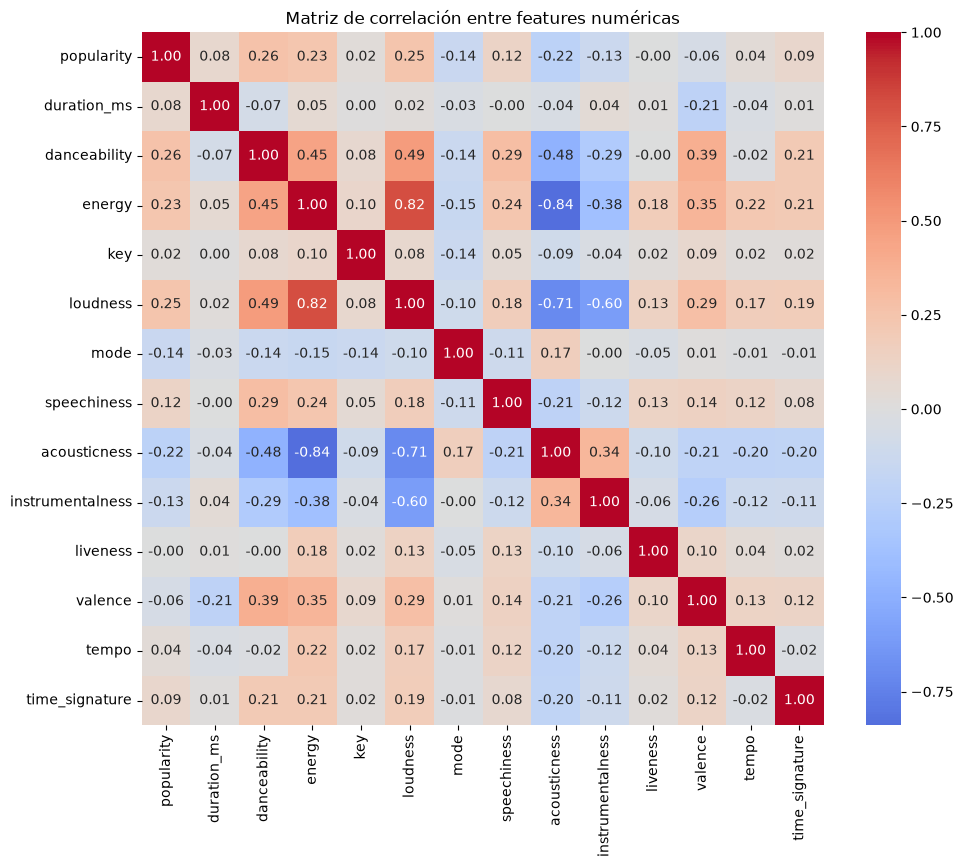

In [35]:
# Visualización 3: matriz de correlación entre features numéricas
num_cols = ["popularity","duration_ms","danceability","energy","key","loudness","mode",
            "speechiness","acousticness","instrumentalness","liveness","valence","tempo","time_signature"]

plt.figure(figsize=(11,9))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación entre features numéricas")
plt.show()

### Distribución de duraciones

Hay un grupo de 30 canciones con duraciones extremas, lo que genera una distribución muy asimétrica a la derecha. Estos valores parecen legítimos (temas más largos) más que errores de carga, así que **no los eliminamos**, pero sí se les aplica Log Transformation en el preprocesamiento para que no dominen en modelos sensibles a la magnitud.

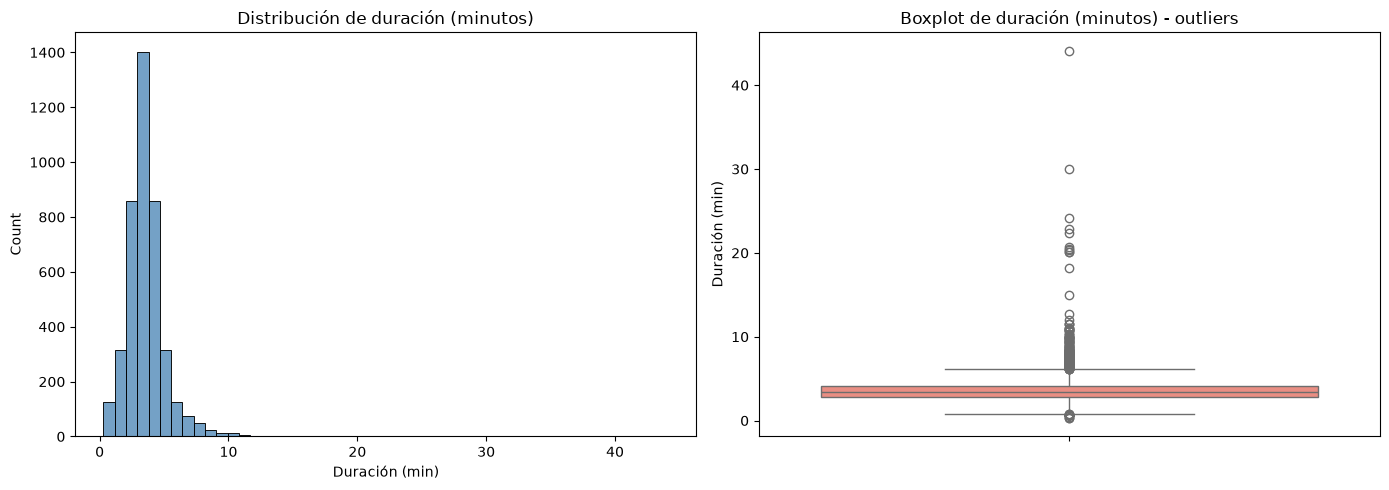

Canciones con más de 10 minutos: 30 de 4200


In [36]:
# Visualización 4: distribución de duration_ms y outliers
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.histplot(df["duration_ms"]/1000/60, bins=50, ax=axes[0], color="steelblue")
axes[0].set_title("Distribución de duración (minutos)")
axes[0].set_xlabel("Duración (min)")

sns.boxplot(y=df["duration_ms"]/1000/60, ax=axes[1], color="salmon")
axes[1].set_title("Boxplot de duración (minutos) - outliers")
axes[1].set_ylabel("Duración (min)")
plt.tight_layout()
plt.show()

outliers = df[df["duration_ms"] > 600000]
print(f"Canciones con más de 10 minutos: {len(outliers)} de {len(df)}")


## 3. Preprocesamiento de los datos

Se descarta *Id* (identificador secuencial sin relación) y lo guardamos para después armar la submission para Kaggle. **Expected** también, porque es la etiqueta que queremos predecir. **LabelEncoder** convierte los géneros en números y permite recuperar sus nombres al generar el CSV.

Tratamos **key** y **time_signature** como categorías. CatBoost recibe estas columnas como texto. Para LightGBM las codificamos con **One Hot Encoding** y completamos eventuales faltantes numéricos con la mediana mediante **SimpleImputer**. Concatenamos ambas matrices con **np.concatenate**.

Cada codificador, imputador y escalador se ajusta únicamente con los datos de entrenamiento de la partición correspondiente. Para los árboles conservamos las variables numéricas en su escala original. Para calcular distancias entre canciones usamos **Standard Scaling**, como se detalla en la búsqueda del ensamble.

In [39]:
def preparar_datos(datos):
    datos = datos[columnas].copy()
    datos['explicit'] = datos['explicit'].astype(float)
    for columna in categorical:
        datos[columna] = datos[columna].astype(str)
    return datos


def preparar_lightgbm(datos_train, datos_consulta):
    codificador = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    imputador = SimpleImputer(strategy='median')
    train_cat = codificador.fit_transform(datos_train[categorical])
    consulta_cat = codificador.transform(datos_consulta[categorical])
    train_num = imputador.fit_transform(datos_train[numerical_cols])
    consulta_num = imputador.transform(datos_consulta[numerical_cols])
    return (np.concatenate([train_cat, train_num], axis=1),
            np.concatenate([consulta_cat, consulta_num], axis=1))

## 4. Criterios de evaluación

Elegimos los hiperparámetros principales maximizando **F1 macro**, que calcula F1 para cada género y promedia dando el mismo peso a todos. También calculamos **MAP@3**, que evalúa la posición del género correcto entre las tres opciones con mayor probabilidad.

**evaluar_probabilidades** devuelve el F1 medio y su desvío entre particiones, el F1 calculado sobre todas las predicciones de validación juntas y MAP@3. El F1 medio y el F1 global pueden diferir porque F1 no es una métrica lineal. En la sección 8 explicamos y comprobamos el cálculo de **map3**.

In [40]:
def normalizar(probabilidades):
    probabilidades = np.asarray(probabilidades, dtype=float)
    return probabilidades / probabilidades.sum(axis=1, keepdims=True)


def map3(y_real, probabilidades):
    orden = np.argsort(-probabilidades, axis=1, kind='stable')[:, :3]
    aciertos = orden == np.asarray(y_real)[:, None]
    return float((aciertos / np.arange(1, 4)).sum(axis=1).mean())


def evaluar_probabilidades(y_real, probabilidades, particiones):
    probabilidades = normalizar(probabilidades)
    f1_particiones = [
        f1_score(y_real[validacion], probabilidades[validacion].argmax(axis=1), average='macro')
        for _, validacion in particiones
    ]
    return {
        'F1_medio': float(np.mean(f1_particiones)),
        'desvio_F1': float(np.std(f1_particiones)),
        'F1_global': float(f1_score(y_real, probabilidades.argmax(axis=1), average='macro')),
        'MAP@3': map3(y_real, probabilidades),
    }

## 5. Modelos y optimización de hiperparámetros con Optuna

Optuna evalúa una función objetivo y propone valores dentro de los rangos que definimos. Usamos **TPESampler**, con cinco pruebas iniciales antes de orientar las propuestas a partir de los resultados. La primera prueba de cada estudio usa una configuración inicial explícita; también se entrena y puntúa dentro de Optuna. Para utilizar esta librería acudimos a la [documentación de Optuna](https://optuna.readthedocs.io/en/stable/tutorial/10_key_features/001_first.html).

Realizamos **20 pruebas para CatBoost** y **20 para LightGBM** con las mismas tres particiones estratificadas del conjunto de desarrollo. En cada prueba, entrenamos en dos partes y predecimos la restante, rotando hasta evaluar todas las canciones. La función objetivo devuelve el promedio de F1 macro de las tres particiones.

Elegimos la mejor prueba de cada familia. Después generamos sus predicciones con cinco particiones y realizamos un tercer estudio de **40 pruebas** para elegir el peso de cada modelo, el radio de vecinos y el aporte de sus etiquetas. Los puntajes de tres y cinco particiones se presentan por separado. Los hiperparámetros explorados de los modelos y los parámetros del ensamble se seleccionan mediante estos tres estudios de Optuna.

**CatBoost** y **LightGBM** combinan árboles mediante boosting. CatBoost procesa las categorías indicadas en **categorical**; LightGBM utiliza la matriz numérica que prepara nuestra función. La búsqueda permite ajustar la complejidad y la regularización de cada modelo.

### Valores explorados

| Modelo | Hiperparámetro | Valores o intervalo |
|---|---|---|
| CatBoost | **iterations** | 800, 1200 o 1600 |
| CatBoost | **depth** | Enteros de 5 a 8 |
| CatBoost | **learning_rate** | De 0,02 a 0,10, en escala logarítmica |
| CatBoost | **l2_leaf_reg** | De 1 a 10, en escala logarítmica |
| CatBoost | **random_strength** | 0, 0,3 o 1 |
| CatBoost | **rsm** | De 0,8 a 1 |
| LightGBM | **n_estimators** | 500, 750 o 1000 |
| LightGBM | **num_leaves** | 9, 15, 31 o 63 |
| LightGBM | **learning_rate** | De 0,015 a 0,08, en escala logarítmica |
| LightGBM | **min_child_samples** | 15, 30 o 50 |
| LightGBM | **subsample** | De 0,65 a 1 |
| LightGBM | **colsample_bytree** | De 0,6 a 1 |
| LightGBM | **reg_lambda** | De 0,001 a 10, en escala logarítmica |
| LightGBM | **reg_alpha** | 0, 0,1 o 1 |

La cantidad y la complejidad de los árboles, la tasa de aprendizaje y la regularización se evalúan conjuntamente. Los rangos y la cantidad de pruebas son decisiones del experimento, por lo que no garantizan encontrar un óptimo global. Los argumentos que no aparecen en la tabla se mantienen fijos y se muestran en **crear_modelo**.

In [42]:
particiones_3 = list(StratifiedKFold(n_splits=3, shuffle=True, random_state=random_state).split(X_train, y_train))
particiones_5 = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=random_state).split(X_train, y_train))

In [43]:
def crear_modelo(familia, parametros):
    if familia == 'cat':
        configuracion = {
            'loss_function': 'MultiClass', 'cat_features': categorical,
            'one_hot_max_size': 12, 'boosting_type': 'Plain',
            'border_count': 254, 'bagging_temperature': 1.0,
            'random_seed': random_state, 'thread_count': n_jobs,
            'verbose': False, 'allow_writing_files': False,
        }
        configuracion.update(parametros)
        return CatBoostClassifier(**configuracion)
    configuracion = {
        'subsample_freq': 1, 'random_state': random_state,
        'n_jobs': n_jobs, 'verbosity': -1,
    }
    configuracion.update(parametros)
    return LGBMClassifier(**configuracion)


def validar_modelo(familia, parametros, particiones):
    probabilidades = np.zeros((len(X_train), num_clases))
    for entrenamiento, validacion in particiones:
        datos_train = preparar_datos(X_train.iloc[entrenamiento])
        datos_val = preparar_datos(X_train.iloc[validacion])
        if familia == 'lgb':
            datos_train, datos_val = preparar_lightgbm(datos_train, datos_val)
        modelo = crear_modelo(familia, parametros)
        with threadpool_limits(limits=n_jobs):
            modelo.fit(datos_train, y_train[entrenamiento])
            probabilidades[validacion] = normalizar(modelo.predict_proba(datos_val))
        assert np.array_equal(modelo.classes_, np.arange(num_clases))
    return evaluar_probabilidades(y_train, probabilidades, particiones), probabilidades

In [44]:
def sugerir_parametros(ensayo, familia):
    if familia == 'cat':
        return {
            'iterations': ensayo.suggest_categorical('iterations', [800, 1200, 1600]),
            'depth': ensayo.suggest_int('depth', 5, 8),
            'learning_rate': ensayo.suggest_float('learning_rate', 0.02, 0.10, log=True),
            'l2_leaf_reg': ensayo.suggest_float('l2_leaf_reg', 1.0, 10.0, log=True),
            'random_strength': ensayo.suggest_categorical('random_strength', [0.0, 0.3, 1.0]),
            'rsm': ensayo.suggest_float('rsm', 0.8, 1.0),
        }
    return {
        'n_estimators': ensayo.suggest_categorical('n_estimators', [500, 750, 1000]),
        'num_leaves': ensayo.suggest_categorical('num_leaves', [9, 15, 31, 63]),
        'learning_rate': ensayo.suggest_float('learning_rate', 0.015, 0.08, log=True),
        'min_child_samples': ensayo.suggest_categorical('min_child_samples', [15, 30, 50]),
        'subsample': ensayo.suggest_float('subsample', 0.65, 1.0),
        'colsample_bytree': ensayo.suggest_float('colsample_bytree', 0.6, 1.0),
        'reg_lambda': ensayo.suggest_float('reg_lambda', 0.001, 10.0, log=True),
        'reg_alpha': ensayo.suggest_categorical('reg_alpha', [0.0, 0.1, 1.0]),
    }


def buscar_modelo(familia, cantidad_pruebas, guardar_avance=None):
    import optuna
    def objetivo(ensayo):
        parametros = sugerir_parametros(ensayo, familia)
        resultado, _ = validar_modelo(familia, parametros, particiones_3)
        ensayo.set_user_attr('metricas', resultado)
        return resultado['F1_medio']

    estudio = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=random_state, n_startup_trials=5),
    )
    # Estas configuraciones iniciales también se evalúan como pruebas de Optuna.
    iniciales = {
        'cat': {'iterations': 1200, 'depth': 8, 'learning_rate': 0.05,
                'l2_leaf_reg': 3.0, 'random_strength': 1.0, 'rsm': 1.0},
        'lgb': {'n_estimators': 750, 'num_leaves': 15, 'learning_rate': 0.03,
                'min_child_samples': 30, 'subsample': 0.85, 'colsample_bytree': 0.9,
                'reg_lambda': 0.001, 'reg_alpha': 0.0},
    }
    estudio.enqueue_trial(iniciales[familia])
    callbacks = [] if guardar_avance is None else [guardar_avance]
    estudio.optimize(objetivo, n_trials=cantidad_pruebas, n_jobs=1, callbacks=callbacks)
    return estudio

### Ajuste por vecinos y optimización del ensamble

Combinamos las probabilidades de CatBoost y LightGBM mediante soft voting. Optuna prueba un peso de CatBoost entre **0,10 y 0,90**, en pasos de **0,05**. El peso de LightGBM es el complemento hasta 1.

Para los vecinos usamos las variables de audio, excluyendo **popularity**, y distancias euclidianas después de estandarizar. Probamos radios **0,03**, **0,1** y **0,2**, y aportes vecinales de **0%**, **25%** o **50%**. El ajuste se aplica únicamente si hay vecinos y todos tienen el mismo género. Si no se cumple esa condición, conservamos el voting.

Las probabilidades del ensamble y de los vecinos se obtienen dentro de las mismas cinco particiones, sin que las etiquetas de validación intervengan en el entrenamiento ni en la búsqueda de vecinos. Optuna utiliza su F1 macro medio para elegir la combinación. Esta comparación sigue siendo parte de la selección, no una evaluación independiente.

In [45]:
def probabilidades_vecinos(datos_train, etiquetas_train, datos_consulta, radio):
    scaler = StandardScaler()
    audio_train = scaler.fit_transform(datos_train[columnas_audio].astype(float))
    audio_consulta = scaler.transform(datos_consulta[columnas_audio].astype(float))
    vecinos = NearestNeighbors(radius=radio, n_jobs=n_jobs).fit(audio_train)
    indices = vecinos.radius_neighbors(audio_consulta, return_distance=False)
    frecuencias = np.bincount(etiquetas_train, minlength=num_clases) / len(etiquetas_train)
    probabilidades = np.tile(frecuencias, (len(datos_consulta), 1))
    cantidades = np.array([len(fila) for fila in indices])
    for i, fila in enumerate(indices):
        if len(fila):
            probabilidades[i] = np.bincount(etiquetas_train[fila], minlength=num_clases) / len(fila)
    return probabilidades, cantidades


def combinar_vecinos(proba_voting, proba_vecinos, cantidades, aporte):
    resultado = normalizar(proba_voting).copy()
    usar_vecinos = (cantidades > 0) & (proba_vecinos.max(axis=1) >= 1 - 1e-12)
    resultado[usar_vecinos] = ((1 - aporte) * resultado[usar_vecinos]
                              + aporte * proba_vecinos[usar_vecinos])
    return normalizar(resultado)


def vecinos_validacion(particiones, radio):
    probabilidades = np.zeros((len(X_train), num_clases))
    cantidades = np.zeros(len(X_train), dtype=int)
    for entrenamiento, validacion in particiones:
        probabilidades[validacion], cantidades[validacion] = probabilidades_vecinos(
            X_train.iloc[entrenamiento], y_train[entrenamiento],
            X_train.iloc[validacion], radio,
        )
    return probabilidades, cantidades

In [46]:
def buscar_ensamble(probabilidades_cat, probabilidades_lgb, cantidad_pruebas, guardar_avance=None, criterio='F1_medio'):
    import optuna
    vecinos_por_radio = {
        radio: vecinos_validacion(particiones_5, radio) for radio in [0.03, 0.1, 0.2]
    }
    def objetivo(ensayo):
        peso_cat = ensayo.suggest_float('peso_cat', 0.1, 0.9, step=0.05)
        radio = ensayo.suggest_categorical('radio_vecinos', [0.03, 0.1, 0.2])
        aporte = ensayo.suggest_categorical('peso_vecinos', [0.0, 0.25, 0.5])
        voting = peso_cat * probabilidades_cat + (1 - peso_cat) * probabilidades_lgb
        proba_vecinos, cantidades = vecinos_por_radio[radio]
        proba = combinar_vecinos(voting, proba_vecinos, cantidades, aporte)
        resultado = evaluar_probabilidades(y_train, proba, particiones_5)
        ensayo.set_user_attr('metricas', resultado)
        return resultado[criterio]

    estudio = optuna.create_study(
        direction='maximize',
        sampler=optuna.samplers.TPESampler(seed=random_state, n_startup_trials=5),
    )
    estudio.enqueue_trial({'peso_cat': 0.75, 'radio_vecinos': 0.1, 'peso_vecinos': 0.5})
    callbacks = [] if guardar_avance is None else [guardar_avance]
    estudio.optimize(objetivo, n_trials=cantidad_pruebas, n_jobs=1, callbacks=callbacks)
    return estudio


def registros_estudio(estudio):
    return [
        {'prueba': prueba.number, 'valor_objetivo': prueba.value,
         'parametros': prueba.params, **prueba.user_attrs['metricas']}
        for prueba in estudio.trials if prueba.value is not None
    ]

### Resultados de las búsquedas realizadas

Incluimos los parámetros, las métricas y el registro de las pruebas de los tres estudios. Son resultados obtenidos al ejecutar Optuna con semilla **67**, no valores de ejemplo. Con **repetir_busqueda = False** se utilizan estos resultados para entrenar la entrega.

Si activamos **repetir_busqueda**, el bloque siguiente ejecuta los estudios completos y utiliza sus resultados en todas las secciones posteriores, incluida la generación del CSV. Las tablas detallan qué configuraciones se probaron y qué puntaje obtuvo cada una.

In [47]:
resultados_guardados = {'cat': {'parametros': {'iterations': 1200,
                        'depth': 6,
                        'learning_rate': 0.051299179326501514,
                        'l2_leaf_reg': 1.7384165773642974,
                        'random_strength': 1.0,
                        'rsm': 0.8627855916818532},
         'metricas_3': {'F1_medio': 0.831634405021023,
                        'desvio_F1': 0.015471121179693582,
                        'F1_global': 0.8316738988315996,
                        'MAP@3': 0.8942577030812325},
         'mejor_prueba': 19,
         'metricas_5': {'F1_medio': 0.8299433902337501,
                        'desvio_F1': 0.016171227127837258,
                        'F1_global': 0.8300248762221298,
                        'MAP@3': 0.8939775910364146}},
 'lgb': {'parametros': {'n_estimators': 750,
                        'num_leaves': 63,
                        'learning_rate': 0.02789176154320218,
                        'min_child_samples': 15,
                        'subsample': 0.7567403329967973,
                        'colsample_bytree': 0.6555407954424222,
                        'reg_lambda': 7.951689580061036,
                        'reg_alpha': 0.1},
         'metricas_3': {'F1_medio': 0.8267254680133124,
                        'desvio_F1': 0.016006725295499263,
                        'F1_global': 0.8266599194673073,
                        'MAP@3': 0.8929505135387488},
         'mejor_prueba': 3,
         'metricas_5': {'F1_medio': 0.8305536538240693,
                        'desvio_F1': 0.01647447339238041,
                        'F1_global': 0.830550005667873,
                        'MAP@3': 0.8949112978524743}},
 'ensamble': {'parametros': {'peso_cat': 0.4, 'radio_vecinos': 0.2, 'peso_vecinos': 0.5},
              'metricas_5': {'F1_medio': 0.8351094990851596,
                             'desvio_F1': 0.017088612381953718,
                             'F1_global': 0.8351003342981715,
                             'MAP@3': 0.8977124183006536},
              'mejor_prueba': 16},
 'semilla': 67,
 'versiones': {'optuna': '5.0.0',
               'scikit-learn': '1.9.0',
               'catboost': '1.2.10',
               'lightgbm': '4.7.0',
               'numpy': '2.4.4',
               'pandas': '3.0.5'},
 'train_sha256': 'a5f43132b130f6ad4631cc4aa836dc0539558225dbdd8de26a74f3ebc74cbd5b',
 'duracion_segundos': 422.75652408599854}

In [48]:
pruebas_guardadas_cat = pd.read_csv(StringIO('''prueba,F1_medio,desvio_F1,F1_global,MAP@3,parametros
0,0.8255290799556042,0.015387365806685939,0.8256192656427938,0.8908029878618114,"{""depth"": 8, ""iterations"": 1200, ""l2_leaf_reg"": 3.0, ""learning_rate"": 0.05, ""random_strength"": 1.0, ""rsm"": 1.0}"
1,0.8192226538747961,0.010428267532563103,0.8192708482559058,0.8877684407096171,"{""depth"": 6, ""iterations"": 1200, ""l2_leaf_reg"": 2.4337601796174915, ""learning_rate"": 0.022027578050127315, ""random_strength"": 0.3, ""rsm"": 0.809379061333676}"
2,0.815879637272194,0.010869592675131464,0.8159571762954286,0.8857142857142857,"{""depth"": 6, ""iterations"": 800, ""l2_leaf_reg"": 2.240370817618071, ""learning_rate"": 0.027059710059927494, ""random_strength"": 1.0, ""rsm"": 0.8824508903051935}"
3,0.8259971853752767,0.011521769773562765,0.8260681817570564,0.8920168067226891,"{""depth"": 7, ""iterations"": 1200, ""l2_leaf_reg"": 2.035189964687292, ""learning_rate"": 0.02909103938066247, ""random_strength"": 1.0, ""rsm"": 0.9203849614503881}"
4,0.824888865295109,0.009396402713265967,0.8249701384079442,0.8910364145658264,"{""depth"": 6, ""iterations"": 1600, ""l2_leaf_reg"": 9.185064619406624, ""learning_rate"": 0.04805062851629738, ""random_strength"": 1.0, ""rsm"": 0.8092279957117853}"
5,0.8178396456501331,0.009247773188810605,0.8178641353463253,0.8873482726423904,"{""depth"": 5, ""iterations"": 1200, ""l2_leaf_reg"": 5.081939412266293, ""learning_rate"": 0.029542381330527816, ""random_strength"": 1.0, ""rsm"": 0.9171038652704216}"
6,0.8298737446548653,0.011816166829704253,0.8298628281976557,0.8928104575163399,"{""depth"": 6, ""iterations"": 1200, ""l2_leaf_reg"": 1.1489133098721134, ""learning_rate"": 0.04481410397883554, ""random_strength"": 1.0, ""rsm"": 0.8255215194346038}"
7,0.8277681845824403,0.017335365176204376,0.8277197877090732,0.8921568627450981,"{""depth"": 5, ""iterations"": 1200, ""l2_leaf_reg"": 1.0628948578045714, ""learning_rate"": 0.06487231078010137, ""random_strength"": 1.0, ""rsm"": 0.8664144766353206}"
8,0.8262731286310716,0.011433550822584102,0.8262297932912999,0.8915966386554622,"{""depth"": 7, ""iterations"": 1600, ""l2_leaf_reg"": 1.5454802448806808, ""learning_rate"": 0.04496286898084296, ""random_strength"": 0.3, ""rsm"": 0.8721167354430087}"
9,0.827707758939129,0.018462561034060326,0.8277927325171842,0.89234360410831,"{""depth"": 6, ""iterations"": 1600, ""l2_leaf_reg"": 4.936785109578939, ""learning_rate"": 0.09388520052654964, ""random_strength"": 1.0, ""rsm"": 0.8404144862791461}"
10,0.8161898081813744,0.013322192346291378,0.8162050516729983,0.8860877684407097,"{""depth"": 6, ""iterations"": 1200, ""l2_leaf_reg"": 6.1515109917854955, ""learning_rate"": 0.028342106425417013, ""random_strength"": 0.0, ""rsm"": 0.8206774722689335}"
11,0.82777734522932,0.013680834673318869,0.8278253013428184,0.8930438842203547,"{""depth"": 5, ""iterations"": 1200, ""l2_leaf_reg"": 1.2458496065171876, ""learning_rate"": 0.0539049048517243, ""random_strength"": 1.0, ""rsm"": 0.9220530789418471}"
12,0.8291639822710369,0.013783413720842385,0.8291913366480234,0.8932773109243698,"{""depth"": 5, ""iterations"": 1200, ""l2_leaf_reg"": 2.361158337455808, ""learning_rate"": 0.06407578420502143, ""random_strength"": 1.0, ""rsm"": 0.9364866321464591}"
13,0.8282564894586414,0.01620446801023583,0.8282308967363251,0.892436974789916,"{""depth"": 5, ""iterations"": 1200, ""l2_leaf_reg"": 3.544596180184612, ""learning_rate"": 0.07876363084579821, ""random_strength"": 1.0, ""rsm"": 0.8344279051221497}"
14,0.8240368070040885,0.013637423351421199,0.8240700087140267,0.8909897292250234,"{""depth"": 6, ""iterations"": 800, ""l2_leaf_reg"": 2.6157598992153352, ""learning_rate"": 0.0787261425680332, ""random_strength"": 1.0, ""rsm"": 0.9347033592717455}"
15,0.8234327741302617,0.015377104025126886,0.8234378435257931,0.8901027077497666,"{""depth"": 6, ""iterations"": 1200, ""l2_leaf_reg"": 1.5172327830219838, ""learning_rate"": 0.0477342485045287, ""random_strength"": 1.0, ""rsm"": 0.8113050582724313}"
16,0.824080671965253,0.013136138796116196,0.8241350908072888,0.8905695611577964,"{""depth"": 7, ""iterations"": 1200, ""l2_leaf_reg"": 3.3263175823407307, ""learning_rate"": 0.03441709860347924, ""random_strength"": 1.0, ""rsm"": 0.8732802879703019}"
17,0.8271955949984142,0.01736379290976661,0.8272323341629594,0.8915966386554622,"{""depth"": 7, ""iterations"": 1200, ""l2_leaf_reg"": 1.3675234089750845, ""learning_rate"": 0.031679216372355726, ""random_strength"": 1.0, ""rsm"": 0.8531994912242137}"
18,0.8243932679468317,0.013496081549954842,0.8244131694251718,0.8894024276377218,"{""depth"": 7, ""iterations"": 1200, ""l2_leaf_reg"": 1.2030019836768207, ""learning_rate"": 0.07101130147067226, ""random_strength"": 1.0, ""rsm"": 0.8956962415328726}"
19,0.831634405021023,0.015471121179693582,0.8316738988315996,0.8942577030812325,"{""depth"": 6, ""iterations"": 1200, ""l2_leaf_reg"": 1.7384165773642974, ""learning_rate"": 0.051299179326501514, ""random_strength"": 1.0, ""rsm"": 0.8627855916818532}"
'''))
pruebas_guardadas_cat['parametros'] = pruebas_guardadas_cat['parametros'].apply(json.loads)

In [49]:
pruebas_guardadas_lgb = pd.read_csv(StringIO('''prueba,F1_medio,desvio_F1,F1_global,MAP@3,parametros
0,0.826162334461107,0.016113651806373124,0.8261610830441578,0.892296918767507,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.03, ""min_child_samples"": 30, ""n_estimators"": 750, ""num_leaves"": 15, ""reg_alpha"": 0.0, ""reg_lambda"": 0.001, ""subsample"": 0.85}"
1,0.8200275194720884,0.016760079500340586,0.8200007622247737,0.8879551820728291,"{""colsample_bytree"": 0.7008286033556957, ""learning_rate"": 0.07145331915190106, ""min_child_samples"": 50, ""n_estimators"": 750, ""num_leaves"": 31, ""reg_alpha"": 0.1, ""reg_lambda"": 0.018209866485250133, ""subsample"": 0.8571543247518016}"
2,0.81811833014065,0.013242362874219423,0.8181906827653438,0.8879084967320261,"{""colsample_bytree"": 0.8407699229007761, ""learning_rate"": 0.022148583194817634, ""min_child_samples"": 50, ""n_estimators"": 1000, ""num_leaves"": 15, ""reg_alpha"": 0.1, ""reg_lambda"": 0.04064492062729322, ""subsample"": 0.9836985936191518}"
3,0.8267254680133124,0.016006725295499263,0.8266599194673073,0.8929505135387488,"{""colsample_bytree"": 0.6555407954424222, ""learning_rate"": 0.02789176154320218, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 7.951689580061036, ""subsample"": 0.7567403329967973}"
4,0.8242976545399688,0.013626532848163272,0.8243507190767337,0.8907563025210085,"{""colsample_bytree"": 0.9287591522171121, ""learning_rate"": 0.04653598515222528, ""min_child_samples"": 15, ""n_estimators"": 500, ""num_leaves"": 15, ""reg_alpha"": 0.0, ""reg_lambda"": 0.35627989576969954, ""subsample"": 0.8087431578235842}"
5,0.8261835449868448,0.01652760731985316,0.8261030763167009,0.892577030812325,"{""colsample_bytree"": 0.8825466083976743, ""learning_rate"": 0.01884168676741347, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.19645155163016836, ""subsample"": 0.6604849563556816}"
6,0.8243156973071559,0.01678878068206529,0.8242609311163603,0.8921568627450981,"{""colsample_bytree"": 0.6884438660544281, ""learning_rate"": 0.037541686880054555, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 1.0, ""reg_lambda"": 1.6316195775285545, ""subsample"": 0.7158703952130867}"
7,0.825482117994878,0.016957154505391977,0.8254132845899681,0.8922502334267041,"{""colsample_bytree"": 0.6816651339786731, ""learning_rate"": 0.02016225543055618, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 15, ""reg_alpha"": 0.1, ""reg_lambda"": 2.6302452366739675, ""subsample"": 0.7041279533218905}"
8,0.8215979672343847,0.017894285404005856,0.8215818331949601,0.8886087768440709,"{""colsample_bytree"": 0.7433007335660745, ""learning_rate"": 0.05295541601440951, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.002190345408042084, ""subsample"": 0.6964746511653661}"
9,0.8215738207592684,0.010120514409211448,0.8215924602533556,0.8904761904761904,"{""colsample_bytree"": 0.834410173260619, ""learning_rate"": 0.045860399284926495, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.15643413840025666, ""subsample"": 0.9246021928210789}"
10,0.8201669090381616,0.009544170577028171,0.820193163838954,0.8897292250233427,"{""colsample_bytree"": 0.9454376433328437, ""learning_rate"": 0.015380362419407, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.13425761101937705, ""subsample"": 0.9848633280670875}"
11,0.8220403535815924,0.01701324349426952,0.8220147122630741,0.8893557422969187,"{""colsample_bytree"": 0.8238804080198547, ""learning_rate"": 0.020105095200396435, ""min_child_samples"": 50, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 7.513846681420981, ""subsample"": 0.7037238639958051}"
12,0.8216582869164094,0.013736544688731733,0.8216467529235284,0.8909897292250234,"{""colsample_bytree"": 0.7211355631372637, ""learning_rate"": 0.023328286439636088, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.038657852030980266, ""subsample"": 0.780090137240963}"
13,0.8226745919273575,0.016825856640337457,0.8226307710078963,0.8913632119514473,"{""colsample_bytree"": 0.7667955559505993, ""learning_rate"": 0.027285761421236426, ""min_child_samples"": 15, ""n_estimators"": 500, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 1.1541285102507677, ""subsample"": 0.802641798572468}"
14,0.8234779505457985,0.01773897732208059,0.823417008873955,0.8909897292250233,"{""colsample_bytree"": 0.6319186458111004, ""learning_rate"": 0.03193894803905812, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.12888899957938865, ""subsample"": 0.6763331363619447}"
15,0.82356788839012,0.016594399084576324,0.8236179916404592,0.8908496732026144,"{""colsample_bytree"": 0.9092534158416333, ""learning_rate"": 0.024483357530115556, ""min_child_samples"": 50, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.14443030812310123, ""subsample"": 0.6603539031657704}"
16,0.8221112627734342,0.016397062615943158,0.822145907689832,0.8901027077497665,"{""colsample_bytree"": 0.8712650723196128, ""learning_rate"": 0.025442411728957292, ""min_child_samples"": 15, ""n_estimators"": 1000, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.01757239287269943, ""subsample"": 0.6975332877520946}"
17,0.824828644494903,0.01797481701997916,0.8247765384212592,0.89234360410831,"{""colsample_bytree"": 0.7359177028651859, ""learning_rate"": 0.01517372787475178, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 0.13788710433995177, ""subsample"": 0.6630765986617552}"
18,0.8253577919203057,0.014585534261775255,0.8253318201529987,0.8930438842203547,"{""colsample_bytree"": 0.8497155217868212, ""learning_rate"": 0.01532660009885975, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 31, ""reg_alpha"": 0.1, ""reg_lambda"": 0.29885212202124595, ""subsample"": 0.6857167814928135}"
19,0.8263755379040919,0.018772369242784265,0.8263618564069642,0.8929505135387488,"{""colsample_bytree"": 0.6900190681043283, ""learning_rate"": 0.01952012471733664, ""min_child_samples"": 15, ""n_estimators"": 750, ""num_leaves"": 63, ""reg_alpha"": 0.1, ""reg_lambda"": 6.350860067003488, ""subsample"": 0.7974243086147866}"
'''))
pruebas_guardadas_lgb['parametros'] = pruebas_guardadas_lgb['parametros'].apply(json.loads)

In [50]:
pruebas_guardadas_ensamble = pd.read_csv(StringIO('''prueba,F1_medio,desvio_F1,F1_global,MAP@3,parametros
0,0.8337613744457617,0.015555989022822478,0.8338395111194572,0.8961718020541549,"{""peso_cat"": 0.75, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.1}"
1,0.8328469650299505,0.018738308824381586,0.8328882063527329,0.8967320261437908,"{""peso_cat"": 0.55, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.03}"
2,0.8315391742055388,0.017471300542382936,0.8316064190946585,0.8954248366013071,"{""peso_cat"": 0.85, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.2}"
3,0.8321457218301813,0.017682210549162757,0.8322127243651614,0.8957516339869281,"{""peso_cat"": 0.25, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.03}"
4,0.8332788147684729,0.015251290898170356,0.833350989064994,0.895985060690943,"{""peso_cat"": 0.9, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.1}"
5,0.8341518802653913,0.01645655232323588,0.8341886507147361,0.8968253968253969,"{""peso_cat"": 0.30000000000000004, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.1}"
6,0.8305157141131103,0.017216746333781605,0.8305217123150309,0.8951914098972922,"{""peso_cat"": 0.1, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.1}"
7,0.8347537624383202,0.01669649944507025,0.834773104170332,0.8972455648926237,"{""peso_cat"": 0.30000000000000004, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
8,0.8334102288537737,0.017473438853078727,0.8333902261482663,0.8969187675070028,"{""peso_cat"": 0.15000000000000002, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
9,0.8328538934817393,0.017978488973208827,0.8328500397173716,0.8965452847805789,"{""peso_cat"": 0.45000000000000007, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.2}"
10,0.8346043975169136,0.018109054666425307,0.8346170670330193,0.8977591036414566,"{""peso_cat"": 0.55, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
11,0.8337565295814962,0.016430313998604396,0.8337838489179697,0.8971988795518208,"{""peso_cat"": 0.6, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
12,0.8350685270277326,0.016663951442450253,0.8350763063324537,0.8973856209150327,"{""peso_cat"": 0.35, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
13,0.8336244759645025,0.016226112128972306,0.8336490098188776,0.896498599439776,"{""peso_cat"": 0.35, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.03}"
14,0.8350685270277326,0.016663951442450253,0.8350763063324537,0.8973856209150327,"{""peso_cat"": 0.35, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
15,0.8335925546852394,0.01732134156276593,0.8336316986140565,0.8966853408029879,"{""peso_cat"": 0.35, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.2}"
16,0.8351094990851596,0.017088612381953718,0.8351003342981715,0.8977124183006536,"{""peso_cat"": 0.4, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
17,0.8328902897941008,0.0174245604699164,0.8329446947658984,0.89640522875817,"{""peso_cat"": 0.65, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.2}"
18,0.8323396842442177,0.017538544971236324,0.8323778615628209,0.8960784313725491,"{""peso_cat"": 0.65, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.1}"
19,0.8345622508892652,0.01799448236191964,0.8345697317462065,0.8973856209150326,"{""peso_cat"": 0.5, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.1}"
20,0.8348895433689496,0.017488388007451536,0.8348645091468314,0.8975723622782447,"{""peso_cat"": 0.45000000000000007, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
21,0.8310700701026171,0.017048614309492897,0.831086181625262,0.8956582633053222,"{""peso_cat"": 0.1, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.2}"
22,0.8318669999978742,0.017797382040376036,0.8319292492177813,0.8956582633053222,"{""peso_cat"": 0.25, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.2}"
23,0.8351094990851596,0.017088612381953718,0.8351003342981715,0.8977124183006536,"{""peso_cat"": 0.4, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
24,0.8348895433689496,0.017488388007451536,0.8348645091468314,0.8975723622782447,"{""peso_cat"": 0.45000000000000007, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
25,0.8329188748472431,0.015744360576322534,0.8329987497029339,0.895704948646125,"{""peso_cat"": 0.75, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.03}"
26,0.833679493329052,0.018753178739142725,0.8337082569134963,0.8971055088702147,"{""peso_cat"": 0.5, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.2}"
27,0.8336290995978333,0.017508650710069386,0.8336536167649403,0.8968720821661998,"{""peso_cat"": 0.4, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.1}"
28,0.833076508615773,0.017613490263564107,0.8330855635039658,0.8965919701213819,"{""peso_cat"": 0.4, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.03}"
29,0.8324190572853267,0.017594192407535066,0.8324939184078636,0.8960784313725491,"{""peso_cat"": 0.25, ""peso_vecinos"": 0.25, ""radio_vecinos"": 0.2}"
30,0.8319662599083715,0.017093572021855942,0.8319620975143076,0.896031746031746,"{""peso_cat"": 0.15000000000000002, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.03}"
31,0.8350685270277326,0.016663951442450253,0.8350763063324537,0.8973856209150327,"{""peso_cat"": 0.35, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
32,0.8338967545103163,0.01675355215148563,0.8339384810043429,0.8967787114845939,"{""peso_cat"": 0.25, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
33,0.8328095838573149,0.01721500906322203,0.8328054859037252,0.896498599439776,"{""peso_cat"": 0.15000000000000002, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.1}"
34,0.8334454740802721,0.016883219580013178,0.8334359438742732,0.8966853408029879,"{""peso_cat"": 0.45000000000000007, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.03}"
35,0.8347537624383202,0.01669649944507025,0.834773104170332,0.8972455648926237,"{""peso_cat"": 0.30000000000000004, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
36,0.8317176530259699,0.01722990771123594,0.8317676883541912,0.8961718020541549,"{""peso_cat"": 0.6, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.2}"
37,0.831568226057302,0.016671386410857286,0.8316459602245753,0.8952380952380953,"{""peso_cat"": 0.9, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.03}"
38,0.8351094990851596,0.017088612381953718,0.8351003342981715,0.8977124183006536,"{""peso_cat"": 0.4, ""peso_vecinos"": 0.5, ""radio_vecinos"": 0.2}"
39,0.8310653468704823,0.017724425010013426,0.8311080353201792,0.8953314659197013,"{""peso_cat"": 0.2, ""peso_vecinos"": 0.0, ""radio_vecinos"": 0.03}"
'''))
pruebas_guardadas_ensamble['parametros'] = pruebas_guardadas_ensamble['parametros'].apply(json.loads)

In [51]:
if repetir_busqueda:
    inicio_busqueda = time.perf_counter()
    estudios = {}
    resultados_optuna = {}
    registros = {}
    for familia in ['cat', 'lgb']:
        estudios[familia] = buscar_modelo(familia, pruebas_por_modelo)
        estudio = estudios[familia]
        resultados_optuna[familia] = {
            'parametros': estudio.best_params,
            'metricas_3': estudio.best_trial.user_attrs['metricas'],
            'mejor_prueba': estudio.best_trial.number,
        }
        registros[familia] = pd.DataFrame(registros_estudio(estudio))
        print(familia, '- mejor F1 en tres particiones:', estudio.best_value, flush=True)

    probabilidades_cv = {}
    for familia in ['cat', 'lgb']:
        metricas, proba = validar_modelo(familia, resultados_optuna[familia]['parametros'], particiones_5)
        resultados_optuna[familia]['metricas_5'] = metricas
        probabilidades_cv[familia] = proba
    estudio_ensamble = buscar_ensamble(probabilidades_cv['cat'], probabilidades_cv['lgb'], pruebas_ensamble)
    resultados_optuna['ensamble'] = {
        'parametros': estudio_ensamble.best_params,
        'metricas_5': estudio_ensamble.best_trial.user_attrs['metricas'],
        'mejor_prueba': estudio_ensamble.best_trial.number,
    }
    registros['ensamble'] = pd.DataFrame(registros_estudio(estudio_ensamble))
    resultados_optuna['semilla'] = random_state
    resultados_optuna['duracion_segundos'] = time.perf_counter() - inicio_busqueda
    (salida / 'resultados_optuna_recalculados.json').write_text(
        json.dumps(resultados_optuna, ensure_ascii=False, indent=2)
    )
    for nombre, tabla in registros.items():
        tabla.to_csv(salida / ('optuna_' + nombre + '_recalculado.csv'), index=False)
else:
    assert random_state == resultados_guardados['semilla'], 'Cambió la semilla: activar repetir_busqueda.'
    assert hashlib.sha256((carpeta / 'train.csv').read_bytes()).hexdigest() == resultados_guardados['train_sha256'], 'Cambió train.csv: activar repetir_busqueda.'
    resultados_optuna = copy.deepcopy(resultados_guardados)
    registros = {'cat': pruebas_guardadas_cat, 'lgb': pruebas_guardadas_lgb,
                 'ensamble': pruebas_guardadas_ensamble}
    print('Se utilizan los resultados guardados de Optuna; las búsquedas no se repiten.')

for nombre, tabla in registros.items():
    print('Estudio:', nombre, '- pruebas:', len(tabla))
    display(tabla.sort_values('F1_medio', ascending=False).reset_index(drop=True))

Se utilizan los resultados guardados de Optuna; las búsquedas no se repiten.
Estudio: cat - pruebas: 20


,prueba,F1_medio,desvio_F1,F1_global,MAP@3,parametros
0,19,0.831634,0.015471,0.831674,0.894258,"{'depth': 6, 'iterations': 1200, 'l2_leaf_reg'..."
1,6,0.829874,0.011816,0.829863,0.892810,"{'depth': 6, 'iterations': 1200, 'l2_leaf_reg'..."
2,12,0.829164,0.013783,0.829191,0.893277,"{'depth': 5, 'iterations': 1200, 'l2_leaf_reg'..."
3,13,0.828256,0.016204,0.828231,0.892437,"{'depth': 5, 'iterations': 1200, 'l2_leaf_reg'..."
4,11,0.827777,0.013681,0.827825,0.893044,"{'depth': 5, 'iterations': 1200, 'l2_leaf_reg'..."
5,7,0.827768,0.017335,0.827720,0.892157,"{'depth': 5, 'iterations': 1200, 'l2_leaf_reg'..."
6,9,0.827708,0.018463,0.827793,0.892344,"{'depth': 6, 'iterations': 1600, 'l2_leaf_reg'..."
7,17,0.827196,0.017364,0.827232,0.891597,"{'depth': 7, 'iterations': 1200, 'l2_leaf_reg'..."
8,8,0.826273,0.011434,0.826230,0.891597,"{'depth': 7, 'iterations': 1600, 'l2_leaf_reg'..."
9,3,0.825997,0.011522,0.826068,0.892017,"{'depth': 7, 'iterations': 1200, 'l2_leaf_reg'..."


Estudio: lgb - pruebas: 20


,prueba,F1_medio,desvio_F1,F1_global,MAP@3,parametros
0,3,0.826725,0.016007,0.826660,0.892951,"{'colsample_bytree': 0.6555407954424222, 'lear..."
1,19,0.826376,0.018772,0.826362,0.892951,"{'colsample_bytree': 0.6900190681043283, 'lear..."
2,5,0.826184,0.016528,0.826103,0.892577,"{'colsample_bytree': 0.8825466083976743, 'lear..."
3,0,0.826162,0.016114,0.826161,0.892297,"{'colsample_bytree': 0.9, 'learning_rate': 0.0..."
4,7,0.825482,0.016957,0.825413,0.892250,"{'colsample_bytree': 0.6816651339786731, 'lear..."
5,18,0.825358,0.014586,0.825332,0.893044,"{'colsample_bytree': 0.8497155217868212, 'lear..."
6,17,0.824829,0.017975,0.824777,0.892344,"{'colsample_bytree': 0.7359177028651859, 'lear..."
7,6,0.824316,0.016789,0.824261,0.892157,"{'colsample_bytree': 0.6884438660544281, 'lear..."
8,4,0.824298,0.013627,0.824351,0.890756,"{'colsample_bytree': 0.9287591522171121, 'lear..."
9,15,0.823568,0.016594,0.823618,0.890850,"{'colsample_bytree': 0.9092534158416333, 'lear..."


Estudio: ensamble - pruebas: 40


,prueba,F1_medio,desvio_F1,F1_global,MAP@3,parametros
0,16,0.835109,0.017089,0.835100,0.897712,"{'peso_cat': 0.4, 'peso_vecinos': 0.5, 'radio_..."
1,38,0.835109,0.017089,0.835100,0.897712,"{'peso_cat': 0.4, 'peso_vecinos': 0.5, 'radio_..."
2,23,0.835109,0.017089,0.835100,0.897712,"{'peso_cat': 0.4, 'peso_vecinos': 0.5, 'radio_..."
3,14,0.835069,0.016664,0.835076,0.897386,"{'peso_cat': 0.35, 'peso_vecinos': 0.5, 'radio..."
4,12,0.835069,0.016664,0.835076,0.897386,"{'peso_cat': 0.35, 'peso_vecinos': 0.5, 'radio..."
5,31,0.835069,0.016664,0.835076,0.897386,"{'peso_cat': 0.35, 'peso_vecinos': 0.5, 'radio..."
6,24,0.834890,0.017488,0.834865,0.897572,"{'peso_cat': 0.45000000000000007, 'peso_vecino..."
7,20,0.834890,0.017488,0.834865,0.897572,"{'peso_cat': 0.45000000000000007, 'peso_vecino..."
8,35,0.834754,0.016696,0.834773,0.897246,"{'peso_cat': 0.30000000000000004, 'peso_vecino..."
9,7,0.834754,0.016696,0.834773,0.897246,"{'peso_cat': 0.30000000000000004, 'peso_vecino..."


## 6. Configuración elegida y validación cruzada

Tomamos los parámetros de la mejor prueba de cada estudio de F1 macro. Generamos las predicciones de CatBoost y LightGBM con las mismas **cinco particiones estratificadas**. Cada canción se predice con un modelo que no la utilizó para entrenar. Si acabamos de repetir la búsqueda, reutilizamos estas predicciones. Si cargamos los resultados guardados, las recalculamos.

Comparamos los modelos individuales, el promedio ponderado (**Voting**) y el mismo promedio con ajuste por vecinos (**Ensamble final**). Los resultados de validación cruzada forman parte de la selección y no deben interpretarse como una evaluación independiente: las etiquetas de desarrollo intervienen en la elección de los parámetros.

In [52]:
parametros_cat = resultados_optuna['cat']['parametros']
parametros_lgb = resultados_optuna['lgb']['parametros']
parametros_ensamble = resultados_optuna['ensamble']['parametros']
peso_cat = parametros_ensamble['peso_cat']
peso_lgb = 1 - peso_cat
radio_vecinos = parametros_ensamble['radio_vecinos']
peso_vecinos = parametros_ensamble['peso_vecinos']

print('CatBoost:', parametros_cat)
print('LightGBM:', parametros_lgb)
print('Ensamble:', parametros_ensamble)

CatBoost: {'iterations': 1200, 'depth': 6, 'learning_rate': 0.051299179326501514, 'l2_leaf_reg': 1.7384165773642974, 'random_strength': 1.0, 'rsm': 0.8627855916818532}
LightGBM: {'n_estimators': 750, 'num_leaves': 63, 'learning_rate': 0.02789176154320218, 'min_child_samples': 15, 'subsample': 0.7567403329967973, 'colsample_bytree': 0.6555407954424222, 'reg_lambda': 7.951689580061036, 'reg_alpha': 0.1}
Ensamble: {'peso_cat': 0.4, 'radio_vecinos': 0.2, 'peso_vecinos': 0.5}


In [53]:
if not repetir_busqueda:
    probabilidades_cv = {}
    for familia in ['cat', 'lgb']:
        metricas, proba = validar_modelo(
            familia, resultados_optuna[familia]['parametros'], particiones_5
        )
        resultados_optuna[familia]['metricas_5'] = metricas
        probabilidades_cv[familia] = proba

voting_cv = peso_cat * probabilidades_cv['cat'] + peso_lgb * probabilidades_cv['lgb']
vecinos_cv, cantidad_cv = vecinos_validacion(particiones_5, radio_vecinos)
proba_cv = combinar_vecinos(voting_cv, vecinos_cv, cantidad_cv, peso_vecinos)
probabilidades_cv_modelos = {
    'CatBoost': probabilidades_cv['cat'],
    'LightGBM': probabilidades_cv['lgb'],
    'Voting': voting_cv,
    'Ensamble final': proba_cv,
}
comparacion_cv = pd.DataFrame([
    {'modelo': nombre, **evaluar_probabilidades(y_train, proba, particiones_5)}
    for nombre, proba in probabilidades_cv_modelos.items()
])
display(comparacion_cv.round(5))
comparacion_cv.to_csv(salida / 'comparacion_cv.csv', index=False)

,modelo,F1_medio,desvio_F1,F1_global,MAP@3
0,CatBoost,0.82994,0.01617,0.83002,0.89398
1,LightGBM,0.83055,0.01647,0.83055,0.89491
2,Voting,0.83308,0.01761,0.83309,0.89659
3,Ensamble final,0.83511,0.01709,0.83510,0.89771


La cantidad de árboles y la tasa de aprendizaje determinan cómo se acumulan las correcciones de cada modelo. La profundidad, la cantidad de hojas y los parámetros de regularización limitan su complejidad. Los valores seleccionados se muestran en la salida de la celda anterior.

Para cada género calculamos **proba_voting = peso_cat × proba_cat + peso_lgb × proba_lgb**. Cuando se cumple la condición de unanimidad entre vecinos, combinamos esas probabilidades con la distribución de sus etiquetas según **peso_vecinos**. Un aporte vecinal de cero deja las probabilidades del voting sin ajuste.

## 7. Evaluación sobre la reserva

Entrenamos los dos modelos con las **3.570 canciones de desarrollo** y predecimos las **630 canciones de reserva**. El codificador de categorías, el imputador y el escalador de vecinos se ajustan con desarrollo. Combinamos las probabilidades con los parámetros elegidos por Optuna, sin usar las etiquetas de reserva para modificarlos.

In [54]:
datos_train = preparar_datos(X_train)
datos_reserva = preparar_datos(X_reserva)
train_lgb, reserva_lgb = preparar_lightgbm(datos_train, datos_reserva)

cat_reserva = crear_modelo('cat', parametros_cat)
lgb_reserva = crear_modelo('lgb', parametros_lgb)
with threadpool_limits(limits=n_jobs):
    cat_reserva.fit(datos_train, y_train)
    lgb_reserva.fit(train_lgb, y_train)
    proba_reserva_cat = normalizar(cat_reserva.predict_proba(datos_reserva))
    proba_reserva_lgb = normalizar(lgb_reserva.predict_proba(reserva_lgb))
assert np.array_equal(cat_reserva.classes_, np.arange(num_clases))
assert np.array_equal(lgb_reserva.classes_, np.arange(num_clases))

voting_reserva = peso_cat * proba_reserva_cat + peso_lgb * proba_reserva_lgb
vecinos_reserva, cantidad_reserva = probabilidades_vecinos(
    X_train, y_train, X_reserva, radio_vecinos
)
proba_reserva = combinar_vecinos(voting_reserva, vecinos_reserva, cantidad_reserva, peso_vecinos)

## 8. Implementación de MAP@3

Como cada canción tiene un solo género verdadero, MAP@3 se obtiene asignando **1** si el género correcto queda primero, **1/2** si queda segundo, **1/3** si queda tercero y **0** si queda fuera de las tres primeras posiciones. Promediamos esos valores entre todas las canciones.

La función **map3**, definida en la sección 4 para utilizarla durante la búsqueda, ordena las columnas de probabilidades de mayor a menor. El orden de esas columnas coincide con **generos**. Si hay un empate, conserva el orden de las clases para que el cálculo sea reproducible.

Comprobamos la función con cuatro ejemplos y mostramos las tres primeras opciones para algunas canciones de la reserva.

In [55]:
# La clase verdadera es la 0: queda primera, segunda, tercera y cuarta.
proba_ejemplo = np.array([
    [0.7, 0.1, 0.1, 0.1],
    [0.3, 0.5, 0.1, 0.1],
    [0.2, 0.4, 0.3, 0.1],
    [0.1, 0.4, 0.3, 0.2],
])
map_ejemplo = map3(np.zeros(4, dtype=int), proba_ejemplo)
assert np.isclose(map_ejemplo, (1 + 1/2 + 1/3 + 0) / 4)
print('MAP@3 del ejemplo:', round(map_ejemplo, 5))

top3_reserva = np.argsort(-proba_reserva, axis=1, kind='stable')[:, :3]
ejemplos_reserva = pd.DataFrame({
    'género verdadero': label_encoder.inverse_transform(y_reserva[:8]),
    'primera opción': generos[top3_reserva[:8, 0]],
    'segunda opción': generos[top3_reserva[:8, 1]],
    'tercera opción': generos[top3_reserva[:8, 2]],
})
display(ejemplos_reserva)
print('MAP@3 del ensamble en reserva:', round(map3(y_reserva, proba_reserva), 5))

MAP@3 del ejemplo: 0.45833


,género verdadero,primera opción,segunda opción,tercera opción
0,hip-hop,hip-hop,acoustic,electronic
1,electronic,electronic,rock,jazz
2,hip-hop,hip-hop,electronic,acoustic
3,classical,classical,jazz,electronic
4,classical,classical,jazz,acoustic
5,rock,rock,jazz,acoustic
6,rock,hip-hop,rock,acoustic
7,hip-hop,hip-hop,electronic,acoustic


MAP@3 del ensamble en reserva: 0.89735


## 9. Comparación de modelos: F1 macro vs. MAP@3

Comparamos CatBoost, LightGBM, Voting y el ensamble con vecinos sobre las mismas canciones de reserva. Agregamos el F1 medio de validación cruzada como referencia del criterio que usamos para seleccionar la configuración.

F1 macro evalúa una única etiqueta por canción y pondera los géneros por igual. MAP@3 considera hasta tres posiciones y promedia por canción. Por eso sus valores no son intercambiables y el orden entre modelos puede cambiar según la métrica.

,modelo,F1_macro_CV,desvio_F1_CV,F1_macro_reserva,MAP@3_reserva
3,Ensamble final,0.83511,0.01709,0.83191,0.89735
2,Voting,0.83308,0.01761,0.82572,0.89339
1,LightGBM,0.83055,0.01647,0.82068,0.89233
0,CatBoost,0.82994,0.01617,0.82570,0.89339


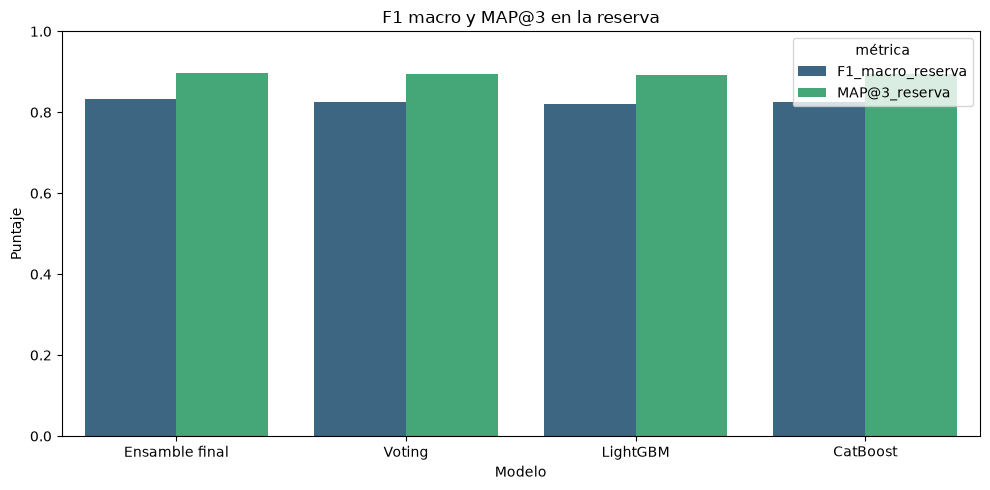

In [56]:
probabilidades_reserva_modelos = {
    'CatBoost': proba_reserva_cat,
    'LightGBM': proba_reserva_lgb,
    'Voting': voting_reserva,
    'Ensamble final': proba_reserva,
}
comparacion_reserva = pd.DataFrame([
    {'modelo': nombre,
     'F1_macro_reserva': f1_score(y_reserva, proba.argmax(axis=1), average='macro'),
     'MAP@3_reserva': map3(y_reserva, proba)}
    for nombre, proba in probabilidades_reserva_modelos.items()
])
comparacion = comparacion_cv[['modelo', 'F1_medio', 'desvio_F1']].rename(
    columns={'F1_medio': 'F1_macro_CV', 'desvio_F1': 'desvio_F1_CV'}
).merge(comparacion_reserva, on='modelo').sort_values('F1_macro_CV', ascending=False)
display(comparacion.round(5))
comparacion.to_csv(salida / 'comparacion_modelos.csv', index=False)

grafico_comparacion = comparacion.melt(
    id_vars='modelo', value_vars=['F1_macro_reserva', 'MAP@3_reserva'],
    var_name='métrica', value_name='valor'
)
plt.figure(figsize=(10, 5))
sns.barplot(data=grafico_comparacion, x='modelo', y='valor', hue='métrica', palette='viridis')
plt.title('F1 macro y MAP@3 en la reserva')
plt.ylim(0, 1)
plt.xlabel('Modelo')
plt.ylabel('Puntaje')
plt.tight_layout()
plt.show()

La matriz de confusión muestra los aciertos y las confusiones del **Ensamble final** al elegir una única clase. Las filas corresponden al género verdadero y las columnas al predicho. El reporte agrega precisión, recall y F1 por género, para que el promedio no oculte diferencias entre clases.

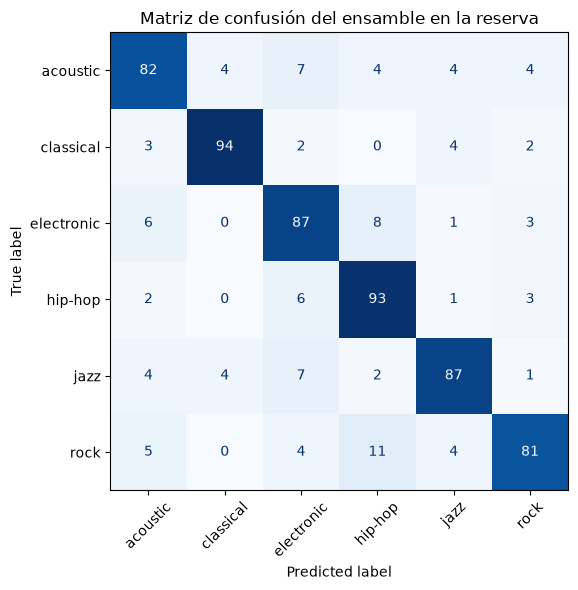

              precision    recall  f1-score   support

    acoustic       0.80      0.78      0.79       105
   classical       0.92      0.90      0.91       105
  electronic       0.77      0.83      0.80       105
     hip-hop       0.79      0.89      0.83       105
        jazz       0.86      0.83      0.84       105
        rock       0.86      0.77      0.81       105

    accuracy                           0.83       630
   macro avg       0.83      0.83      0.83       630
weighted avg       0.83      0.83      0.83       630



In [57]:
fig, ax = plt.subplots(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    y_reserva, proba_reserva.argmax(axis=1), display_labels=generos,
    cmap='Blues', xticks_rotation=45, colorbar=False, ax=ax,
)
ax.set_title('Matriz de confusión del ensamble en la reserva')
plt.tight_layout()
plt.show()
print(classification_report(y_reserva, proba_reserva.argmax(axis=1),
                            target_names=generos, zero_division=0))

## 10. Optimización orientada a MAP@3

Si el objetivo es presentar tres géneros posibles, conviene seleccionar los parámetros con MAP@3. Evaluamos tres alternativas al ensamble elegido por F1 macro:

- **Calibración isotónica:** ajustamos las probabilidades usando las predicciones de validación cruzada de desarrollo y sus etiquetas. Luego aplicamos ese ajuste a la reserva.
- **Promedio simple:** asignamos 50% a CatBoost y 50% a LightGBM, sin ajuste por vecinos.
- **Optuna con objetivo MAP@3:** probamos 40 combinaciones de pesos y vecinos con las predicciones de cinco particiones. Mantenemos los hiperparámetros de los dos modelos elegidos en la búsqueda de F1 macro; esta búsqueda adicional optimiza únicamente la combinación.

La calibración busca que las probabilidades reflejen mejor la frecuencia de aciertos. No garantiza mejorar el ranking ni conservar la clase más probable. Medimos sus efectos sobre F1 macro y MAP@3, en lugar de suponer una mejora.

### Calibración del ensamble

Ajustamos una **IsotonicRegression** por género, usando como entrada su probabilidad y como respuesta si la canción pertenece a ese género. Aplicamos las funciones aprendidas a las probabilidades de reserva y normalizamos cada fila para que sume uno. Usamos predicciones de desarrollo obtenidas fuera de la partición de entrenamiento; las etiquetas de reserva no intervienen en el ajuste. [Documentación de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.isotonic.IsotonicRegression.html).

In [58]:
calibradores = []
proba_calibrada = np.zeros_like(proba_reserva)
for clase in range(num_clases):
    calibrador = IsotonicRegression(y_min=0, y_max=1, out_of_bounds='clip')
    calibrador.fit(proba_cv[:, clase], (y_train == clase).astype(int))
    proba_calibrada[:, clase] = calibrador.predict(proba_reserva[:, clase])
    calibradores.append(calibrador)

# Si todos los ajustes devolvieran cero, conservamos la distribución original.
filas_sin_masa = proba_calibrada.sum(axis=1) == 0
proba_calibrada[filas_sin_masa] = proba_reserva[filas_sin_masa]
proba_calibrada = normalizar(proba_calibrada)
proba_promedio = normalizar(0.5 * proba_reserva_cat + 0.5 * proba_reserva_lgb)

### Búsqueda de la combinación con Optuna

Reutilizamos **buscar_ensamble**, cambiando el criterio a **MAP@3**. El estudio utiliza únicamente las predicciones y etiquetas de desarrollo. La reserva se evalúa después de fijar la combinación ganadora. Guardamos el detalle de las 40 pruebas para poder revisar cómo se obtuvo el resultado.

In [59]:
estudio_map3 = buscar_ensamble(
    probabilidades_cv['cat'], probabilidades_cv['lgb'],
    pruebas_ensamble, criterio='MAP@3'
)
parametros_map3 = estudio_map3.best_params
pruebas_map3 = pd.DataFrame(registros_estudio(estudio_map3))
print('Parámetros elegidos para MAP@3:', parametros_map3)
print('Mejor MAP@3 en desarrollo:', round(estudio_map3.best_value, 5))
display(pruebas_map3.sort_values('MAP@3', ascending=False).reset_index(drop=True))
pruebas_map3.to_csv(salida / 'optuna_map3.csv', index=False)

peso_cat_map3 = parametros_map3['peso_cat']
voting_reserva_map3 = (peso_cat_map3 * proba_reserva_cat
                       + (1 - peso_cat_map3) * proba_reserva_lgb)
vecinos_reserva_map3, cantidad_reserva_map3 = probabilidades_vecinos(
    X_train, y_train, X_reserva, parametros_map3['radio_vecinos']
)
proba_reserva_map3 = combinar_vecinos(
    voting_reserva_map3, vecinos_reserva_map3, cantidad_reserva_map3,
    parametros_map3['peso_vecinos']
)

Parámetros elegidos para MAP@3: {'peso_cat': 0.5, 'radio_vecinos': 0.2, 'peso_vecinos': 0.5}
Mejor MAP@3 en desarrollo: 0.89781


,prueba,valor_objetivo,parametros,F1_medio,desvio_F1,F1_global,MAP@3
0,39,0.897806,"{'peso_cat': 0.5, 'radio_vecinos': 0.2, 'peso_...",0.835162,0.018346,0.835156,0.897806
1,26,0.897806,"{'peso_cat': 0.5, 'radio_vecinos': 0.2, 'peso_...",0.835162,0.018346,0.835156,0.897806
2,27,0.897806,"{'peso_cat': 0.5, 'radio_vecinos': 0.2, 'peso_...",0.835162,0.018346,0.835156,0.897806
3,25,0.897806,"{'peso_cat': 0.5, 'radio_vecinos': 0.2, 'peso_...",0.835162,0.018346,0.835156,0.897806
4,38,0.897806,"{'peso_cat': 0.5, 'radio_vecinos': 0.2, 'peso_...",0.835162,0.018346,0.835156,0.897806
5,28,0.897759,"{'peso_cat': 0.55, 'radio_vecinos': 0.2, 'peso...",0.834604,0.018109,0.834617,0.897759
6,31,0.897759,"{'peso_cat': 0.55, 'radio_vecinos': 0.2, 'peso...",0.834604,0.018109,0.834617,0.897759
7,24,0.897712,"{'peso_cat': 0.4, 'radio_vecinos': 0.2, 'peso_...",0.835109,0.017089,0.835100,0.897712
8,37,0.897572,"{'peso_cat': 0.45000000000000007, 'radio_vecin...",0.834890,0.017488,0.834865,0.897572
9,23,0.897386,"{'peso_cat': 0.35, 'radio_vecinos': 0.2, 'peso...",0.835069,0.016664,0.835076,0.897386


In [60]:
estrategias_map3 = {
    'Ensamble elegido por F1': proba_reserva,
    'Ensamble calibrado': proba_calibrada,
    'Promedio 50/50': proba_promedio,
    'Ensamble elegido por MAP@3': proba_reserva_map3,
}
comparacion_map3 = pd.DataFrame([
    {'estrategia': nombre,
     'F1_macro_reserva': f1_score(y_reserva, proba.argmax(axis=1), average='macro'),
     'MAP@3_reserva': map3(y_reserva, proba)}
    for nombre, proba in estrategias_map3.items()
])
comparacion_map3['diferencia_MAP@3'] = (
    comparacion_map3['MAP@3_reserva'] - map3(y_reserva, proba_reserva)
)
display(comparacion_map3.round(5))
comparacion_map3.to_csv(salida / 'comparacion_estrategias_map3.csv', index=False)
for fila in comparacion_map3.iloc[1:].itertuples(index=False, name=None):
    nombre, f1, puntaje_map3, diferencia = fila
    print(f'{nombre}: MAP@3 = {puntaje_map3:.5f}; diferencia frente al ensamble de F1 = {diferencia:+.5f}')

,estrategia,F1_macro_reserva,MAP@3_reserva,diferencia_MAP@3
0,Ensamble elegido por F1,0.83191,0.89735,0.00000
1,Ensamble calibrado,0.82708,0.89524,-0.00212
2,Promedio 50/50,0.82735,0.89444,-0.00291
3,Ensamble elegido por MAP@3,0.83356,0.89841,0.00106


Ensamble calibrado: MAP@3 = 0.89524; diferencia frente al ensamble de F1 = -0.00212
Promedio 50/50: MAP@3 = 0.89444; diferencia frente al ensamble de F1 = -0.00291
Ensamble elegido por MAP@3: MAP@3 = 0.89841; diferencia frente al ensamble de F1 = +0.00106


Una mejora en el objetivo de desarrollo puede no trasladarse a la reserva. Además, los modelos base de esta comparación se eligieron por F1 macro; para estudiar una optimización completa de MAP@3 también habría que repetir sus búsquedas con esa función objetivo.

Mantenemos el ensamble elegido por F1 macro para generar el CSV, de acuerdo con el criterio principal del trabajo. Estas alternativas permiten analizar qué cambia cuando interesa el ranking de tres géneros.

## 11. Métricas según el caso de negocio

**F1 macro** resulta útil si tenemos que asignar un único género a cada canción y queremos dar el mismo peso a todos los géneros. Por ejemplo, al organizar un catálogo, combina precisión y recall por clase y evita que los géneros más frecuentes dominen el promedio. No implica que todos los errores tengan el mismo costo económico.

**MAP@3** resulta más adecuada si mostramos tres géneros o categorías posibles y una persona elige entre ellos. Valora que la etiqueta correcta esté entre las primeras opciones, especialmente en la primera posición. En este trabajo evalúa el ranking de géneros, no la calidad completa de un sistema de recomendación de canciones.

**Precisión y recall por género** permiten considerar necesidades específicas: si interesa recuperar la mayor cantidad posible de canciones de jazz, miramos su recall; si queremos reducir canciones mal etiquetadas como jazz, miramos su precisión.

**Una matriz de costos** sería apropiada si ciertas confusiones perjudican más que otras al usuario. Esos costos deben definirse según el uso del sistema, porque ni F1 macro ni MAP@3 los incorporan directamente.

Para la entrega utilizamos una sola etiqueta en **Expected** y mantenemos F1 macro como criterio de selección. La comparación con MAP@3 complementa el análisis cuando el resultado esperado es una lista ordenada.

## 12. Entrenamiento final

Con la configuración de F1 macro fijada, entrenamos CatBoost y LightGBM con las **4.200 canciones etiquetadas**. Ajustamos el preprocesamiento con esos datos y lo aplicamos al test. También buscamos los vecinos de cada canción del test entre las canciones etiquetadas. Las etiquetas del test no están disponibles y no intervienen en ninguna etapa.

In [61]:
X_modelos = preparar_datos(X)
X_submission = preparar_datos(X_kaggle)
X_lgb, X_submission_lgb = preparar_lightgbm(X_modelos, X_submission)
modelo_cat = crear_modelo('cat', parametros_cat)
modelo_lgb = crear_modelo('lgb', parametros_lgb)

inicio = time.perf_counter()
with threadpool_limits(limits=n_jobs):
    modelo_cat.fit(X_modelos, y)
    modelo_lgb.fit(X_lgb, y)
    proba_cat = normalizar(modelo_cat.predict_proba(X_submission))
    proba_lgb = normalizar(modelo_lgb.predict_proba(X_submission_lgb))
assert np.array_equal(modelo_cat.classes_, np.arange(num_clases))
assert np.array_equal(modelo_lgb.classes_, np.arange(num_clases))

proba_voting = peso_cat * proba_cat + peso_lgb * proba_lgb
proba_cercanas, cantidad_vecinos = probabilidades_vecinos(X, y, X_kaggle, radio_vecinos)
proba_final = combinar_vecinos(proba_voting, proba_cercanas, cantidad_vecinos, peso_vecinos)
cambios_vecinos = int((proba_final.argmax(axis=1) != proba_voting.argmax(axis=1)).sum())
print('Entrenamiento y predicción:', round(time.perf_counter() - inicio, 1), 'segundos')
print('Predicciones que cambian por los vecinos:', cambios_vecinos)

Entrenamiento y predicción: 24.7 segundos
Predicciones que cambian por los vecinos: 6


## 13. Generación del archivo para Kaggle

Elegimos el género de mayor probabilidad y recuperamos su nombre con **label_encoder.inverse_transform**. Guardamos las columnas **Id** y **Expected**, ordenadas por identificador. Verificamos que haya una predicción por canción, que no falten valores y que las etiquetas pertenezcan a los seis géneros conocidos.

In [65]:
submission = pd.DataFrame({
    'Id': df_kaggle['Id'].to_numpy(),
    'Expected': label_encoder.inverse_transform(proba_final.argmax(axis=1)),
}).sort_values('Id').reset_index(drop=True)

assert proba_final.shape == (len(df_kaggle), num_clases)
assert np.isfinite(proba_final).all() and np.allclose(proba_final.sum(axis=1), 1)
assert len(submission) == len(df_kaggle) and submission.Id.is_unique
assert set(submission.Id) == set(df_kaggle.Id)
assert submission.Expected.isin(generos).all() and not submission.isna().any().any()

archivo_submission = salida / 'submission.csv'
submission.to_csv(archivo_submission, index=False)
pd.testing.assert_frame_equal(pd.read_csv(archivo_submission), submission)
print('CSV generado:', archivo_submission.resolve())
display(submission.head(10))

CSV generado: C:\Users\timod\Desktop\Facultad\tdvi\tp2-td6\resultados_entrega\submission.csv


,Id,Expected
0,0,classical
1,1,hip-hop
2,3,rock
3,6,acoustic
4,10,rock
5,11,acoustic
6,12,electronic
7,15,electronic
8,25,jazz
9,27,rock


## 14. Conclusiones

El procedimiento integra el preprocesamiento por partición, la búsqueda de hiperparámetros con Optuna, la validación cruzada y la comparación en reserva. Los pesos y el ajuste por vecinos se eligen con resultados de desarrollo; después se utilizan para entrenar sobre todos los datos etiquetados.

Los experimentos de MAP@3 muestran el efecto de cambiar la combinación y calibrar sus probabilidades. La tabla permite identificar si cada alternativa mejora, mantiene o empeora el ranking en esta reserva concreta. El CSV conserva la configuración elegida por F1 macro.

Las métricas de validación y reserva describen el desempeño local. No corresponden al puntaje de Kaggle, que se conoce después de enviar el archivo. La validación cruzada usada para elegir parámetros tampoco reemplaza una evaluación independiente.

In [66]:
fila_final = comparacion_reserva.loc[comparacion_reserva['modelo'] == 'Ensamble final'].iloc[0]
print(f"F1 macro en reserva: {fila_final['F1_macro_reserva']:.5f}")
print(f"MAP@3 en reserva: {fila_final['MAP@3_reserva']:.5f}")
print('Archivo generado:', archivo_submission)
print('Canciones predichas:', len(submission))

F1 macro en reserva: 0.83191
MAP@3 en reserva: 0.89735
Archivo generado: c:\Users\timod\Desktop\Facultad\tdvi\tp2-td6\resultados_entrega\submission.csv
Canciones predichas: 1800
